In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
plt.style.use("seaborn-v0_8-whitegrid")


<h1 face="Times New Roma" color="#3f134f">Random Variables</h1>

<h6>
  <font size="4" face="Times New Roma" color="#3f134f">
    <ul style="margin-left: 30px">
      <li><a href="#what">What is a random variable?</a></li><br>
      <li><a href="#pmf">Probability distribution of $X$</a></li><br>
      <li><a href="#discrete">Discrete vs continuous</a></li><br>
      <li><a href="#pdf">Probability density function (PDF)</a></li><br>
      <li><a href="#var">Variance and standard deviation</a></li><br>
    </ul>
  </font>
</h6>


<h2 id="what" face="Times New Roma" color="#270336">1. What is a random variable?</h2>

A random variable is a numerical value assigned to the outcome of a random experiment.

We usually represent random variables using capital letters:

$$
X,\ Y,\ Z
$$

**Experiment:** toss a coin twice. The sample space is

$$
\Omega = \{HH, HT, TH, TT\}
$$

where $H$ is heads and $T$ is tails.

Define $X$ as the number of heads obtained. Then $X$ maps each outcome to a number:


| Outcome | $X$ (number of heads) |
|---------|-----------------------|
| HH | 2 |
| HT | 1 |
| TH | 1 |
| TT | 0 |


The possible values of $X$ are

$$
X \in \{0,1,2\}
$$

The experiment produces outcomes $\{HH, HT, TH, TT\}$. The random variable converts those outcomes into numbers $\{0, 1, 2\}$.


<h2 id="pmf" face="Times New Roma" color="#270336">1.2 Probability distribution of $X$</h2>

Each value of $X$ collects the outcomes that map to it:


| $X$ | Outcomes | Probability |
|-----|----------|-------------|
| 0 | TT | $1/4$ |
| 1 | HT, TH | $2/4$ |
| 2 | HH | $1/4$ |


So

$$
P(X=0)=0.25,\qquad P(X=1)=0.50,\qquad P(X=2)=0.25
$$


,Outcome,X
0,HH,2
1,HT,1
2,TH,1
3,TT,0


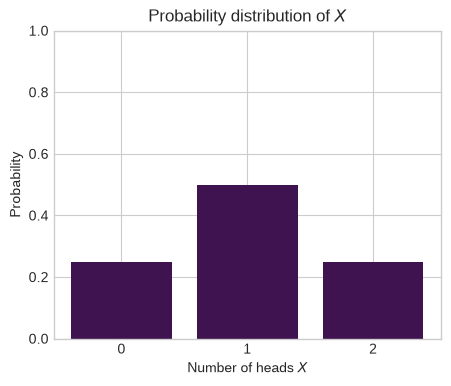

In [2]:
outcomes = ["HH", "HT", "TH", "TT"]
heads = [2, 1, 1, 0]
df = pd.DataFrame({"Outcome": outcomes, "X": heads})
display(df)

probabilities = df["X"].value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(probabilities.index, probabilities.values, color="#3f134f")
ax.set_xlabel("Number of heads $X$")
ax.set_ylabel("Probability")
ax.set_title("Probability distribution of $X$")
ax.set_xticks([0, 1, 2])
ax.set_ylim(0, 1)
plt.show()


<h2 id="discrete" face="Times New Roma" color="#270336">2. Discrete vs continuous</h2>

A **discrete** random variable takes countable values, often whole numbers.

Examples:
- number of heads in 3 tosses: $0,1,2,3$
- number of customers in an hour: $0,1,2,\ldots$
- number of defective items in a batch

For a fair die, let $X$ be the face shown:

$$
X \in \{1,2,3,4,5,6\}, \qquad P(X=x)=\frac{1}{6}
$$

A **continuous** random variable can take any value in an interval (height, time, temperature). Probability is assigned to intervals, not to single points.


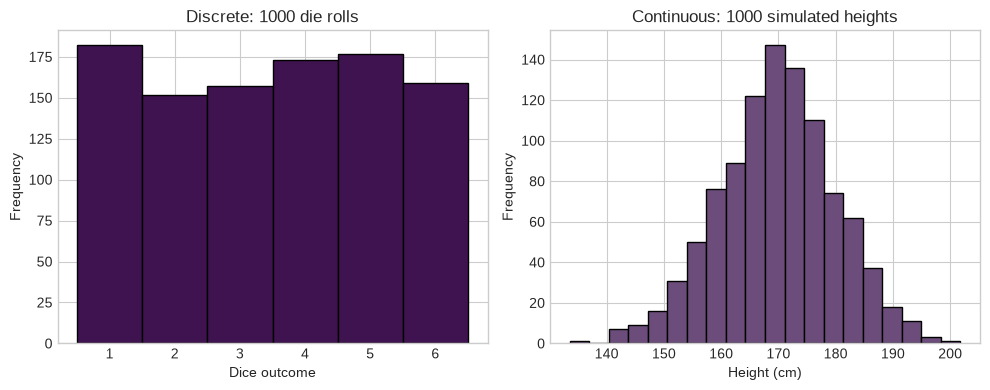

In [3]:
n = 1000
dice_rolls = rng.integers(1, 7, size=n)
heights = rng.normal(loc=170, scale=10, size=n)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(dice_rolls, bins=np.arange(0.5, 7.5, 1), edgecolor="black", color="#3f134f")
axes[0].set_xticks(range(1, 7))
axes[0].set_xlabel("Dice outcome")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Discrete: 1000 die rolls")

axes[1].hist(heights, bins=20, edgecolor="black", color="#6b4c7a")
axes[1].set_xlabel("Height (cm)")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Continuous: 1000 simulated heights")

plt.tight_layout()
plt.show()


<h2 id="pdf" face="Times New Roma" color="#270336">3. Probability density function (PDF)</h2>

The PDF $f(x)$ describes how probability is spread over the values of a continuous random variable.

- **PMF** (discrete): probability of a specific value
- **PDF** (continuous): density; probabilities are areas under the curve

$$
P(a \leq X \leq b) = \int_a^b f(x)\, dx
$$

Rules:

$$
f(x) \ge 0, \qquad \int_{-\infty}^{+\infty} f(x)\, dx = 1
$$

A density value can be greater than $1$. It is not a probability. The total area is still $1$.

For a person's height $X$,

$$
P(165 \le X \le 175)
$$

is the probability that height lies between $165$ cm and $175$ cm. A single point has probability zero:

$$
P(X=170)=0
$$

That does not mean $170$ cm is impossible. Probability is measured on intervals, not on individual points.


Assume heights follow a normal distribution with mean $\mu=170$ cm and standard deviation $\sigma=10$ cm. The PDF is

$$
f(x) = \frac{1}{\sigma \sqrt{2\pi}} \exp\left( -\frac{1}{2} \left( \frac{x-\mu}{\sigma} \right)^{2} \right)
$$


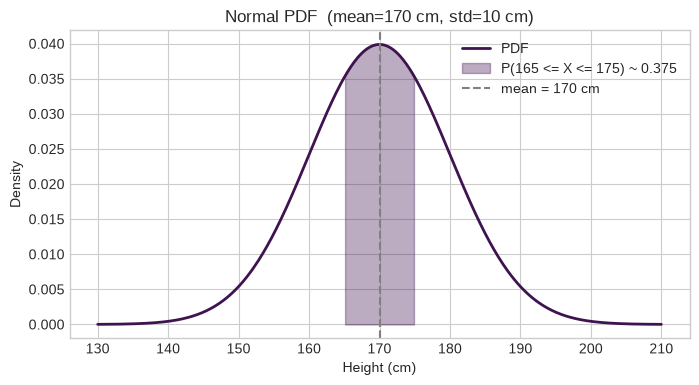

In [4]:
mu, sigma = 170, 10
a, b = 165, 175

x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 500)
z = (x - mu) / sigma
pdf = np.exp(-0.5 * z**2) / (sigma * np.sqrt(2 * np.pi))

in_interval = (x >= a) & (x <= b)
prob = np.trapezoid(pdf[in_interval], x[in_interval])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, pdf, color="#3f134f", lw=2, label="PDF")
ax.fill_between(
    x, pdf, where=in_interval, color="#3f134f", alpha=0.35,
    label=f"P({a} <= X <= {b}) ~ {prob:.3f}",
)
ax.axvline(mu, color="gray", ls="--", label=f"mean = {mu} cm")
ax.set_xlabel("Height (cm)")
ax.set_ylabel("Density")
ax.set_title(f"Normal PDF  (mean={mu} cm, std={sigma} cm)")
ax.legend()
plt.show()

<h2 id="var" face="Times New Roma" color="#270336">4. Variance and standard deviation</h2>

The expected value $\mu = E(X)$ is the average outcome. Two variables can share the same mean and still look very different.

- Investment A: returns usually between $9\%$ and $11\%$
- Investment B: returns swing between $-20\%$ and $40\%$

Both can have mean $10\%$, but B is much more spread out. **Variance** and **standard deviation** measure that spread.

Variance is the expected squared distance from the mean. For a discrete random variable

$$
\mathrm{Var}(X) = \sigma^2 = \sum_x (x-\mu)^2 P(X=x)
$$

where $\mu = E(X)$.


**Example: fair die.** $X \in \{1,2,3,4,5,6\}$ and $P(X=x)=1/6$, so $\mu = E(X)=3.5$.

| $X$ | $X-3.5$ | $(X-3.5)^2$ |
|-----|---------|-------------|
| 1 | $-2.5$ | $6.25$ |
| 2 | $-1.5$ | $2.25$ |
| 3 | $-0.5$ | $0.25$ |
| 4 | $0.5$ | $0.25$ |
| 5 | $1.5$ | $2.25$ |
| 6 | $2.5$ | $6.25$ |

$$
\mathrm{Var}(X) = \frac{6.25+2.25+0.25+0.25+2.25+6.25}{6} = \frac{17.5}{6} \approx 2.9167
$$


**Standard deviation** is the square root of variance, so it uses the same units as $X$ (not squared units):

$$
\sigma = \sqrt{\mathrm{Var}(X)} \approx \sqrt{2.9167} \approx 1.71
$$

An equivalent formula, often nicer in code, is

$$
\mathrm{Var}(X) = E(X^2) - [E(X)]^2
$$

For the die, $E(X^2)=91/6 \approx 15.1667$, so $15.1667 - 3.5^2 = 2.9167$.

For a continuous variable the sum becomes an integral:

$$
\mathrm{Var}(X) = \int_{-\infty}^{+\infty} (x-\mu)^2 f(x)\, dx
$$

If $X \sim N(\mu,\sigma^2)$, then $E(X)=\mu$, $\mathrm{Var}(X)=\sigma^2$, and $\mathrm{SD}(X)=\sigma$. Heights $X \sim N(170, 10^2)$ therefore have standard deviation $10$ cm.


The two datasets below have the same mean $10$, but different spread.


In [ ]:
A = np.array([8, 9, 10, 11, 12])
B = np.array([2, 6, 10, 14, 18])
idx = np.arange(1, 6)

fig, ax = plt.subplots(figsize=(7, 4))
ax.axhline(10, color="gray", ls="--", label="mean = 10")
ax.plot(idx, A, "o-", color="#3f134f", label=f"A  (std {A.std(ddof=0):.2f})")
ax.plot(idx, B, "s--", color="#6b4c7a", label=f"B  (std {B.std(ddof=0):.2f})")
ax.set_xticks(idx)
ax.set_xlabel("observation")
ax.set_ylabel("value")
ax.set_title("Same mean, different spread")
ax.legend()
plt.show()


**Two-coin experiment.** Recall $P(X=0)=0.25$, $P(X=1)=0.50$, $P(X=2)=0.25$.


In [ ]:
values = np.array([0.0, 1.0, 2.0])
probs = np.array([0.25, 0.50, 0.25])

mean = np.sum(values * probs)
var = np.sum((values - mean) ** 2 * probs)
# same number via the computational formula and via weighted average
var_alt = np.sum(values**2 * probs) - mean**2
var_avg = np.average((values - mean) ** 2, weights=probs)

print(f"E(X)  = {mean}")
print(f"Var(X) = {var}  (also {var_alt} and {var_avg})")
print(f"SD(X)  = {np.sqrt(var):.4f}")
